<a href="https://colab.research.google.com/github/Vandana-kannan/Cat-Dog-Image-Classification-CNN/blob/main/cat_dog_agumentation_pratice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from tensorflow import keras

In [2]:
import kagglehub
path = kagglehub.dataset_download("andrewtoh78/cats-and-dogs-dataset")

Using Colab cache for faster access to the 'cats-and-dogs-dataset' dataset.


In [3]:

print(os.listdir(path))


['cats_and_dogs_small']


In [4]:
for root, dirs, files in os.walk(path):
    print(root, "Number of images:", len(files))

/kaggle/input/cats-and-dogs-dataset Number of images: 0
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small Number of images: 0
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/validation Number of images: 0
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/validation/dogs Number of images: 500
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/validation/cats Number of images: 500
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/test Number of images: 0
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/test/dogs Number of images: 500
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/test/cats Number of images: 500
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/train Number of images: 0
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/train/dogs Number of images: 1000
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/train/cats Number of images: 1000


In [5]:
train_dir = r'/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/train'

validation_dir = r'/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/validation'

test_dir = r'/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/test'

In [6]:
import os

print(os.path.exists(train_dir))
print(os.path.exists(validation_dir))
print(os.path.exists(test_dir))

True
True
True


In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [10]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
    )
test_datagen = ImageDataGenerator(rescale=1./255)


In [11]:
train_generator= train_datagen.flow_from_directory(
    train_dir,
    batch_size=32,
    target_size=(150,150),
    class_mode="binary"
)

Found 2000 images belonging to 2 classes.


In [12]:
validation_generator= test_datagen.flow_from_directory(
    validation_dir,
    batch_size=32,
    target_size=(150,150),
    class_mode="binary"
)

Found 1000 images belonging to 2 classes.


In [13]:
from tensorflow.keras import layers
from tensorflow.keras import models

In [14]:
model=models.Sequential()
model.add(layers.Conv2D(32,(3,3),activation='relu',input_shape=(150,150,3)))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Conv2D(64,(3,3,),activation="relu"))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Conv2D(128,(3,3),activation="relu"))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Conv2D(128,(3,3),activation="relu"))
model.add(layers.MaxPooling2D(2,2))
model.add(layers.Flatten())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(512,activation="relu"))
model.add(layers.Dense(1,activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
from tensorflow.keras import optimizers

In [18]:
model.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.RMSprop(learning_rate=1e-4),
    metrics=['acc']
    )

In [19]:
history=model.fit(
    train_generator,
    steps_per_epoch=150,
    epochs=5,
    validation_data=validation_generator,
    validation_steps=100
)

Epoch 1/5
100/150 ━━━━━━━━━━━━━━━━━━━━ 1:01 1s/step - acc: 0.4939 - loss: 0.6941

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


150/150 ━━━━━━━━━━━━━━━━━━━━ 141s 928ms/step - acc: 0.5040 - loss: 0.6935 - val_acc: 0.5070 - val_loss: 0.6869
Epoch 2/5
150/150 ━━━━━━━━━━━━━━━━━━━━ 137s 895ms/step - acc: 0.5500 - loss: 0.6862 - val_acc: 0.5000 - val_loss: 0.7072
Epoch 3/5
150/150 ━━━━━━━━━━━━━━━━━━━━ 147s 927ms/step - acc: 0.5545 - loss: 0.6793 - val_acc: 0.5860 - val_loss: 0.6665
Epoch 4/5
150/150 ━━━━━━━━━━━━━━━━━━━━ 134s 888ms/step - acc: 0.5810 - loss: 0.6687 - val_acc: 0.5930 - val_loss: 0.6585
Epoch 5/5
150/150 ━━━━━━━━━━━━━━━━━━━━ 142s 891ms/step - acc: 0.5895 - loss: 0.6648 - val_acc: 0.5590 - val_loss: 0.7033


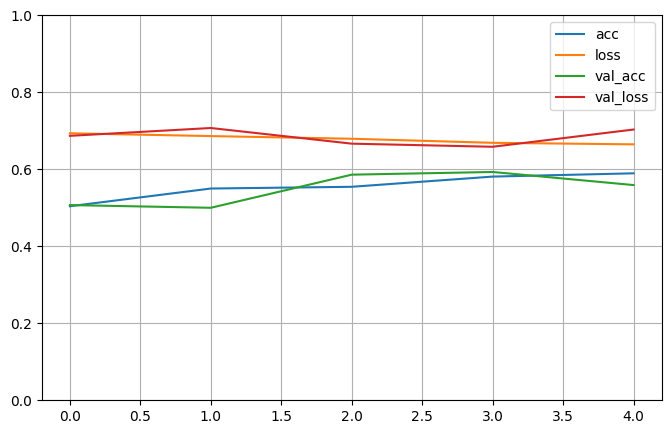

In [20]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()

In [21]:
model.save("cat_dog_model_agument.h5")

In [22]:
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(150,150),
    batch_size=20,
    class_mode='binary',
    shuffle=False
)

Found 1000 images belonging to 2 classes.


In [23]:
test_loss, test_acc = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 313ms/step - acc: 0.5640 - loss: 0.7207
Test Loss: 0.7207313179969788
Test Accuracy: 0.5640000104904175


In [24]:
y_pred = model.predict(test_generator)

50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 299ms/step


In [25]:
import numpy as np

y_pred_classes = (y_pred > 0.5).astype(int).flatten()

y_true = test_generator.classes

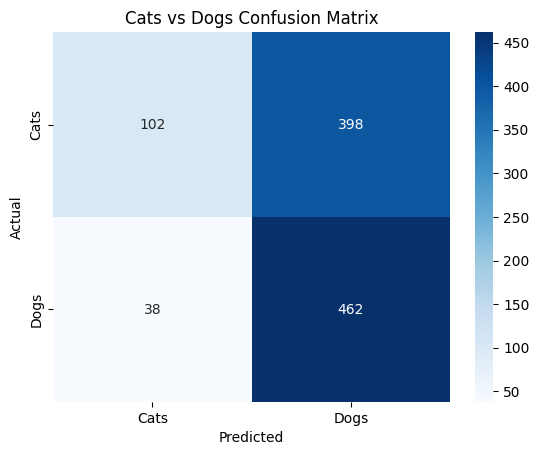

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns


cm = confusion_matrix(y_true, y_pred_classes)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cats', 'Dogs'],
            yticklabels=['Cats', 'Dogs'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Cats vs Dogs Confusion Matrix")
plt.show()

In [28]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred_classes,
    target_names=['Cats', 'Dogs']
))

              precision    recall  f1-score   support

        Cats       0.73      0.20      0.32       500
        Dogs       0.54      0.92      0.68       500

    accuracy                           0.56      1000
   macro avg       0.63      0.56      0.50      1000
weighted avg       0.63      0.56      0.50      1000



In [30]:

cat_path = os.path.join(test_dir, 'cats')
dog_path = os.path.join(test_dir, 'dogs')

cat_image = os.path.join(cat_path, os.listdir(cat_path)[0])
dog_image = os.path.join(dog_path, os.listdir(dog_path)[0])

print(cat_image)
print(dog_image)

/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/test/cats/cat.1994.jpg
/kaggle/input/cats-and-dogs-dataset/cats_and_dogs_small/test/dogs/dog.1942.jpg


In [31]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

img = load_img(cat_image, target_size=(150,150))

img_array = img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

if prediction[0][0] > 0.5:
    print("Predicted: Dog")
else:
    print("Predicted: Cat")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step
Predicted: Dog


In [32]:
img = load_img(dog_image, target_size=(150,150))

img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

if prediction[0][0] > 0.5:
    print("Predicted: Dog")
else:
    print("Predicted: Cat")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Predicted: Dog


In [33]:
model.save("cat_dog_model_auguments.h5")

In [34]:
from tensorflow.keras import backend as k
k.clear_session()
